In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Understanding the data

In [2]:
train = pd.read_csv("train-data.csv")
test = pd.read_csv("test-data.csv")

In [4]:
print("Training shape: ", train.shape)
print("Testing shape: ", test.shape)

Training shape:  (6019, 14)
Testing shape:  (1234, 13)


In [7]:
print("Training cols:")
print(train.columns.tolist())

Training cols:
['Unnamed: 0', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price']


In [8]:
print("Testing cols:")
print(train.columns.tolist())

Testing cols:
['Unnamed: 0', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price']


In [9]:
print("First Five rows: ", train.head())

First Five rows:     Unnamed: 0                              Name    Location  Year  \
0           0            Maruti Wagon R LXI CNG      Mumbai  2010   
1           1  Hyundai Creta 1.6 CRDi SX Option        Pune  2015   
2           2                      Honda Jazz V     Chennai  2011   
3           3                 Maruti Ertiga VDI     Chennai  2012   
4           4   Audi A4 New 2.0 TDI Multitronic  Coimbatore  2013   

   Kilometers_Driven Fuel_Type Transmission Owner_Type     Mileage   Engine  \
0              72000       CNG       Manual      First  26.6 km/kg   998 CC   
1              41000    Diesel       Manual      First  19.67 kmpl  1582 CC   
2              46000    Petrol       Manual      First   18.2 kmpl  1199 CC   
3              87000    Diesel       Manual      First  20.77 kmpl  1248 CC   
4              40670    Diesel    Automatic     Second   15.2 kmpl  1968 CC   

       Power  Seats  New_Price  Price  
0  58.16 bhp    5.0        NaN   1.75  
1  126.2 bhp

In [10]:
print("Train dtypes:", train.dtypes)

Train dtypes: Unnamed: 0             int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
dtype: object


In [12]:
print("Statistical Summary")
print(train.describe().round(2))

Statistical Summary
       Unnamed: 0     Year  Kilometers_Driven    Seats    Price
count     6019.00  6019.00            6019.00  5977.00  6019.00
mean      3009.00  2013.36           58738.38     5.28     9.48
std       1737.68     3.27           91268.84     0.81    11.19
min          0.00  1998.00             171.00     0.00     0.44
25%       1504.50  2011.00           34000.00     5.00     3.50
50%       3009.00  2014.00           53000.00     5.00     5.64
75%       4513.50  2016.00           73000.00     5.00     9.95
max       6018.00  2019.00         6500000.00    10.00   160.00


## Checking Data Quality

Checking Missing vals


In [14]:
print(train.isnull().sum())

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64


Check duplicates

In [16]:
print(train.duplicated().sum())

0


Inspect unusual vals

In [17]:
print(train["Power"].value_counts().head(10))

Power
74 bhp       235
98.6 bhp     131
73.9 bhp     125
140 bhp      123
78.9 bhp     111
67.1 bhp     107
null bhp     107
67.04 bhp    107
82 bhp       101
88.5 bhp     100
Name: count, dtype: int64


In [21]:
print(train["Fuel_Type"].value_counts())
print(train["Transmission"].value_counts())

Fuel_Type
Diesel      3205
Petrol      2746
CNG           56
LPG           10
Electric       2
Name: count, dtype: int64
Transmission
Manual       4299
Automatic    1720
Name: count, dtype: int64


Dropping the row-index col in train-data.csv and test-data.csv

In [ ]:
train = train.drop(columns=["Unnamed: 0"])

In [24]:
test = test.drop(columns=["Unnamed: 0"])

In [25]:
train.head(2)
test.head(2)

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price
0,Maruti Alto K10 LXI CNG,Delhi,2014,40929,CNG,Manual,First,32.26 km/kg,998 CC,58.2 bhp,4.0,NaN
1,Maruti Alto 800 2016-2019 LXI,Coimbatore,2013,54493,Petrol,Manual,Second,24.7 kmpl,796 CC,47.3 bhp,5.0,NaN


# EDA

## Price Distribution

Text(0.5, 1.0, 'Price Distribution of Used Cars')

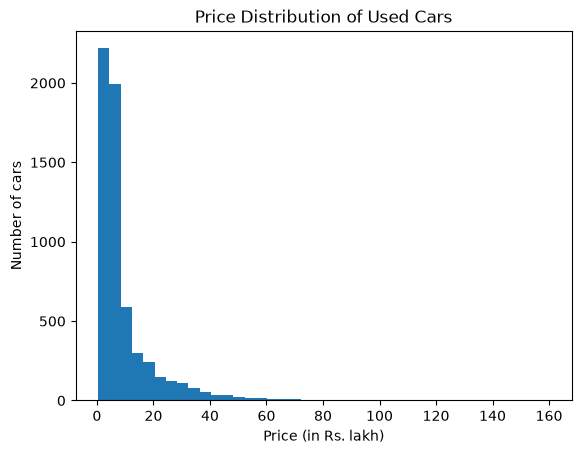

In [31]:
plt.hist(train["Price"], bins=40)
plt.xlabel("Price (in Rs. lakh)")
plt.ylabel("Number of cars")
plt.title("Price Distribution of Used Cars")

In [38]:
train["Price"].describe()

count    6019.000000
mean        9.479468
std        11.187917
min         0.440000
25%         3.500000
50%         5.640000
75%         9.950000
max       160.000000
Name: Price, dtype: float64

## Price vs Manufacturing Year

Text(0.5, 1.0, 'Car Price vs Manufacturing Year')

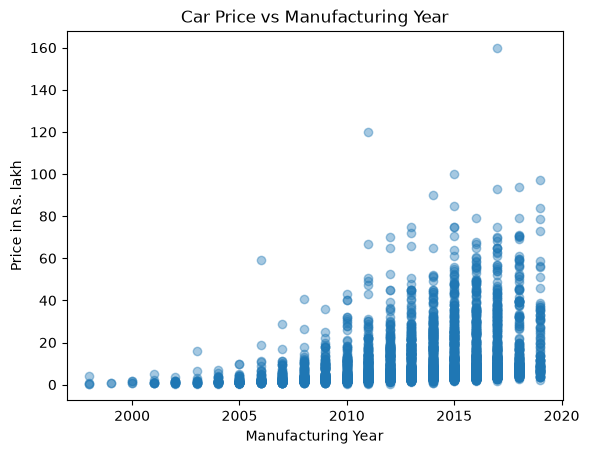

In [39]:
plt.scatter(train["Year"], train["Price"], alpha=0.4)
plt.xlabel("Manufacturing Year")
plt.ylabel("Price in Rs. lakh")
plt.title("Car Price vs Manufacturing Year")

In [45]:
train[["Price", "Year"]].describe()

,Price,Year
count,6019.000000,6019.000000
mean,9.479468,2013.358199
std,11.187917,3.269742
min,0.440000,1998.000000
25%,3.500000,2011.000000
50%,5.640000,2014.000000
75%,9.950000,2016.000000
max,160.000000,2019.000000


## Price vs KM Driven

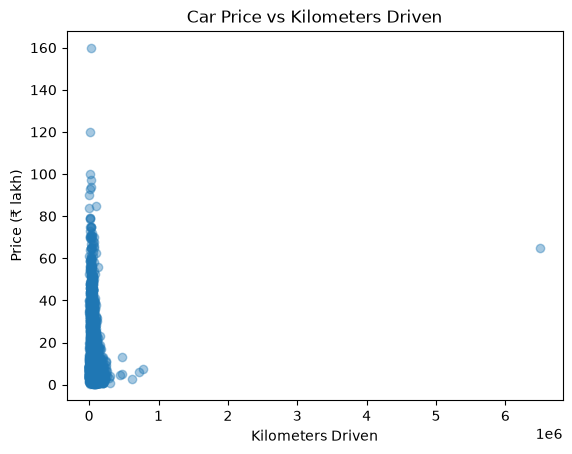

In [46]:
plt.scatter(
    train["Kilometers_Driven"],
    train["Price"],
    alpha=0.4
)
plt.xlabel("Kilometers Driven")
plt.ylabel("Price (₹ lakh)")
plt.title("Car Price vs Kilometers Driven")
plt.show()

In [48]:
train[['Price', 'Year']].corr()


,Price,Year
Price,1.000000,0.305327
Year,0.305327,1.000000


## Price vs Transmission

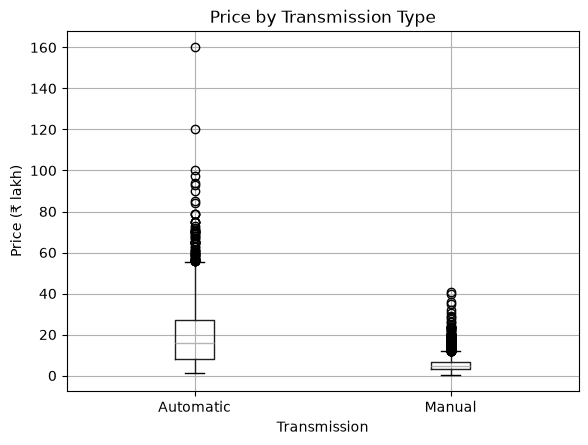

In [49]:
train.boxplot(column="Price", by="Transmission")
plt.xlabel("Transmission")
plt.ylabel("Price (₹ lakh)")
plt.title("Price by Transmission Type")
plt.suptitle("")
plt.show()

## Inspecting Correlations

                       Year  Kilometers_Driven     Seats     Price
Year               1.000000          -0.173048  0.012333  0.305327
Kilometers_Driven -0.173048           1.000000  0.083113 -0.011493
Seats              0.012333           0.083113  1.000000  0.052225
Price              0.305327          -0.011493  0.052225  1.000000


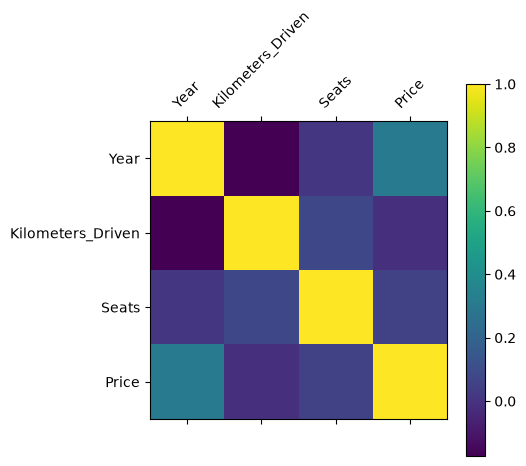

In [50]:
numeric_data = train[
    ["Year", "Kilometers_Driven", "Seats", "Price"]
]

print(numeric_data.corr())

plt.matshow(numeric_data.corr())
plt.xticks(range(len(numeric_data.columns)),
           numeric_data.columns, rotation=45)
plt.yticks(range(len(numeric_data.columns)),
           numeric_data.columns)
plt.colorbar()
plt.show()

# What we derived till now (Till EDA)?

## Dataset Understandings
- Training data: 6,019 rows, 14 columns
- Test data: 1,234 rows, 13 columns
- Target variable: Price (selling price in ₹ lakh)
- Input features include car year, kilometres driven, fuel type, transmission, engine, power, mileage and more.

## Data Quality Issues
- Missing values in Mileage, Engine, Power and Seats.
- New_Price is missing in approximately 86.3% of training rows.
- Mileage, Engine and Power are stored as text and need numeric conversion.
- Unnamed: 0 appears to be a row index and should be removed.
- We found no exact duplicate rows in either dataset.

## EDA


| FInding | Interpretation |
| ---------------- | ---------------- |
| Median Price: Rs 5.64 lakh | Half of the car listed cost below this value |
| Max Price: Rs 160 lakh | Expensive cars create a long upper trail |
| Year-Price correlation = +0.305 | Newer cars tend to have higher prices, but the linear relationship is moderate |
| Kilometres–Price correlation: ≈ −0.011 | Almost no overall linear correlation in the raw data |


# Feature Engineering and preprocessing

## Convert text -> numbers

In [51]:
def extract_numbers(series):
    return pd.to_numeric(
        series.astype(str).str.extract(r"(\d+\.?\d*)")[0],
        errors="coerce"
    )
    
for df in [train, test]:
    df["Mileage"] = extract_numbers(df["Mileage"])
    df["Engine"] = extract_numbers(df["Engine"])
    df["Power"] = extract_numbers(df["Power"])

### Working of conversion

- .astype(str) converts values to text.
- .str.extract(...) extracts the first numeric value.
- pd.to_numeric(..., errors="coerce") converts it to a number and turns unparseable values into NaN (missing values).

For ex: "1197 CC" becomes 1197 and "null bhp" become NaN

## Select features and target

In [52]:
features = [
    "Name",
    "Location",
    "Year",
    "Kilometers_Driven",
    "Fuel_Type",
    "Transmission",
    "Owner_Type",
    "Mileage",
    "Engine",
    "Power",
    "Seats"
]

X = train[features]
y = train["Price"]

X_test_final = test[features]

print("Features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test_final.shape)

Features: (6019, 11)
Target: (6019,)
Test features: (1234, 11)


- X contains the model's input features.
- y contains known selling prices.
- X_test_final contains test-set features for future predictions.

__Never include Price inside X. That would leak the answer to the model.__

## Separate Numerical and Categorical cols

In [53]:
numeric_features = [
    "Year",
    "Kilometers_Driven",
    "Mileage",
    "Engine",
    "Power",
    "Seats"
]

categorical_features = [
    "Name",
    "Location",
    "Fuel_Type",
    "Transmission",
    "Owner_Type"
]

## Missing Vals and encode categories

In [54]:
import sklearn

In [63]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [64]:
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])

In [65]:
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("encoder", OneHotEncoder(handle_unknown="ignore"))
                                 ])

In [66]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

### What this does?

- __SimpleImputer(strategy="median"):__ fills missing numerical values with the median.

- __SimpleImputer(strategy="most_frequent"):__ fills missing categorical values with the most frequent category.

- __OneHotEncoder(...):__ converts categories into numeric indicator columns.

- __handle_unknown="ignore":__ handles categories appearing in the test set that weren't present during training.

- __ColumnTransformer:__ applies the appropriate preprocessing to each group of columns.

- __Pipeline:__ keeps the preprocessing steps together in order.

## Lets verify

In [61]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nFeature count:", len(features))
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Missing values in X:
Name                   0
Location               0
Year                   0
Kilometers_Driven      0
Fuel_Type              0
Transmission           0
Owner_Type             0
Mileage                2
Engine                36
Power                143
Seats                 42
dtype: int64

Feature count: 11
Numerical features: 6
Categorical features: 5


# Split Data and Train MLR

## Splitting train data

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training rows: ", X_train.shape[0])
print("Validation rows: ", X_val.shape[0])


Training rows:  4815
Validation rows:  1204


- __X_train, y_train:__ used to train the model.

- __X_val, y_val:__ reserved to evaluate predictions.

- __test_size=0.2:__ uses 20% of the labelled data for validation.

- __random_state=42:__ makes the split reproducible.

## Create complete model pipeline

In [67]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

__What happens here?__
1. __preprocessor__ fills missing values and encodes categorical features.
2. __LinearRegression()__ learns the relationship between the features and Price.
3. __Pipeline__ runs these steps in order and keeps them together.

## Train the model

In [68]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


### The .fit() method:
- Learns median and most-frequent values from the training data.
- Learns the categories used by the encoder.
- Transforms the training features.
- Learns the Linear Regression coefficients and intercept.
The validation data is not used to fit these steps.

## Generate validation predictions

In [69]:
y_pred = model.predict(X_val)

print("Actual prices:")
print(y_val.head().to_list())

print("Predicted prices:")
print(y_pred[:5])

Actual prices:
[5.75, 10.08, 7.85, 2.4, 1.6]
Predicted prices:
[ 4.59982625 13.39881934 11.6775354   5.96978249  4.58799848]


# Evaluate the model

In [70]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [71]:
mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_pred)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R² Score:", round(r2, 3))

MAE: 3.969
MSE: 67.566
RMSE: 8.22
R² Score: 0.451


__Interpretation:__
- MAE: Average absolute prediction error, in ₹ lakh.
- MSE: Average squared error, in (₹ lakh)².
- RMSE: Error metric in ₹ lakh that penalizes larger mistakes more strongly.
- R²: Measures how much better the model performs than predicting the mean price on this validation set. It can be negative.

## Compare against a baseline

A baseline predicts the average training-set price for every car. Your model should ideally outperform it.

In [72]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

baseline_mae = mean_absolute_error(y_val, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_pred)
)
baseline_r2 = r2_score(y_val, baseline_pred)

print("Baseline MAE:", round(baseline_mae, 3))
print("Model MAE:", round(mae, 3))

print("Baseline RMSE:", round(baseline_rmse, 3))
print("Model RMSE:", round(rmse, 3))

print("Baseline R²:", round(baseline_r2, 3))
print("Model R²:", round(r2, 3))

Baseline MAE: 7.169
Model MAE: 3.969
Baseline RMSE: 11.094
Model RMSE: 8.22
Baseline R²: -0.0
Model R²: 0.451


# Visualize predictions and Analyze residuals

## Actual vs predicted price

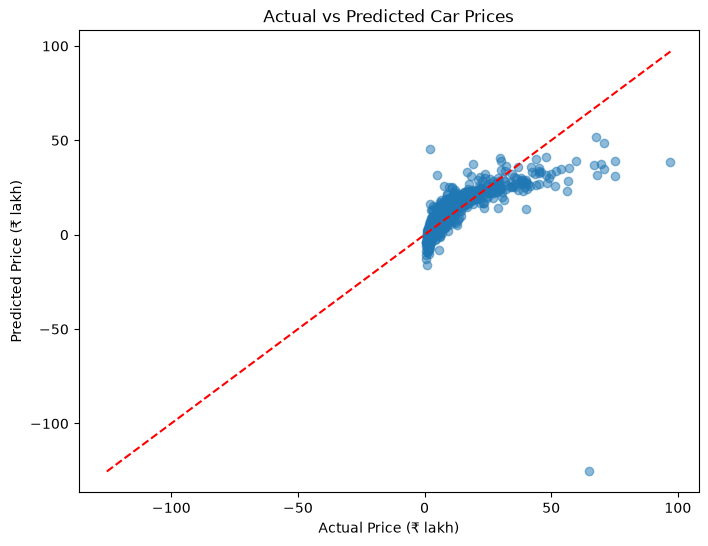

In [73]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred, alpha=0.5)

plt.xlabel("Actual Price (₹ lakh)")
plt.ylabel("Predicted Price (₹ lakh)")
plt.title("Actual vs Predicted Car Prices")

# Reference line: perfect predictions
minimum = min(y_val.min(), y_pred.min())
maximum = max(y_val.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.show()

## Residual calc

Residual = y_Actual - y_predicted

In [74]:
residuals = y_val - y_pred

print("First 10 residuals:")
print(residuals.head(10))

First 10 residuals:
2868     1.150174
5924    -3.318819
3764    -3.827535
4144    -3.569782
2780    -2.987998
1514   -10.403648
1199    -2.355597
84      -0.030596
1219    -7.985641
1554     1.582932
Name: Price, dtype: float64


_Results from Residuals_

__Positive residual:__ the model predicted too low.

__Negative residual:__ the model predicted too high.

__Residual near zero:__ the prediction was close.

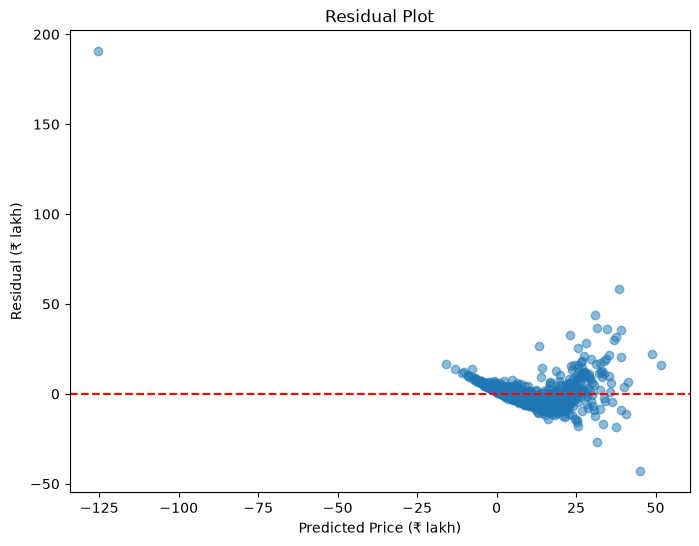

In [75]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Price (₹ lakh)")
plt.ylabel("Residual (₹ lakh)")
plt.title("Residual Plot")

plt.show()

## Inspect largest errors

In [76]:
results = pd.DataFrame({
    "Actual_Price": y_val,
    "Predicted_Price": y_pred,
    "Residual": residuals
})

results["Absolute_Error"] = results["Residual"].abs()

print(
    results.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

      Actual_Price  Predicted_Price    Residual  Absolute_Error
2328         65.00      -125.441053  190.441053      190.441053
1505         97.07        38.560278   58.509722       58.509722
655          75.00        30.876559   44.123441       44.123441
3132          2.02        45.202912  -43.182912       43.182912
5009         68.00        31.608890   36.391110       36.391110
3752         70.66        34.619056   36.040944       36.040944
3489         75.00        39.255180   35.744820       35.744820
5038         56.14        23.120261   33.019739       33.019739
1194         69.50        37.625619   31.874381       31.874381
1038         67.00        36.896799   30.103201       30.103201


# Train Final Model and Save predictions

In [77]:
final_model = model

final_model.fit(X, y)

print("Final model trained on all training data.")

Final model trained on all training data.


## Predicted test prices

In [78]:
test_predictions = final_model.predict(X_test_final)

print(test_predictions[:10])

[ 0.51453384 -1.86219971 19.24163209  5.40725266  5.16557765 16.77730511
 21.06013584 -0.3752901   7.56063211 15.85219758]


## Save Prediction into a CSV File

In [81]:
output = test.copy()
output["Predicted_Price"] = test_predictions

output.to_csv("car_price_predictions.csv", index=False)